In [ ]:
! kaggle datasets download -d vierohernandez/construction-management-terms-and-parameters

Dataset URL: https://www.kaggle.com/datasets/vierohernandez/construction-management-terms-and-parameters
License(s): CC-BY-NC-SA-4.0
construction-management-terms-and-parameters.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
! unzip construction-management-terms-and-parameters.zip

Archive:  construction-management-terms-and-parameters.zip
replace CONSTADEX.ipynb? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
df #uploading dataset

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...,...
3550,3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,3553,5694.837811,617.497125,COMMERCIAL,7,88


In [ ]:
# all the libraries used in this project
import pandas as pd
import numpy as np

import seaborn as sns
import re
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
#from sklearn.neighbours import KNeighborsClassifier
from sklearn import metrics
from sklearn.svm import SVC
from sklearn.metrics import classification_report,confusion_matrix
from sklearn import metrics
from sklearn import preprocessing

import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import export_graphviz

from IPython.display import Image
!pip install pydotplus
import pydotplus
import graphviz
from six import StringIO

import six
import sys
sys.modules['sklearn.externals.six']=six
#from sklearn.externals.six import StringIO

from pydot import graph_from_dot_data
from sklearn.utils import resample


from sklearn.tree import export_graphviz
import pydot
import random

%matplotlib inline


In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
df #uploading dataset

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...,...
3550,3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,3553,5694.837811,617.497125,COMMERCIAL,7,88


In [ ]:
! kaggle datasets download -d vierohernandez/construction-management-terms-and-parameters

Dataset URL: https://www.kaggle.com/datasets/vierohernandez/construction-management-terms-and-parameters
License(s): CC-BY-NC-SA-4.0
construction-management-terms-and-parameters.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
! unzip construction-management-terms-and-parameters.zip

Archive:  construction-management-terms-and-parameters.zip
replace CONSTADEX.ipynb? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
df

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...,...
3550,3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,3553,5694.837811,617.497125,COMMERCIAL,7,88


In [ ]:
to_drop=['Unnamed: 0', 'typology']
df.drop(to_drop, inplace=True, axis=1)

In [ ]:
df.head()

,built_area,modul_price,weeks_delay,weeks_duration
0,16971.669353,800.717684,0,69
1,12434.613919,680.061254,2,92
2,11003.411065,1190.379098,1,45
3,10423.124959,987.449779,4,35
4,22990.708329,564.466572,6,85


In [ ]:
df.index.is_unique
True

True

In [ ]:
df.loc[20]

built_area        7229.069248
modul_price        386.534438
weeks_delay          5.000000
weeks_duration      77.000000
Name: 20, dtype: float64

In [ ]:
pub = df['built_area'].astype(str)
is_7000 = pub.str.contains('7000')
print(is_7000[:10])

0    False
1    False
2    False
3    False
4    False
5    False
6    False
7    False
8    False
9    False
Name: built_area, dtype: bool


In [ ]:
#Exploratory Data analysis
df.isin([0]).sum() #no.of zeros in the dataset

built_area          0
modul_price         0
weeks_delay       164
weeks_duration      0
dtype: int64

In [ ]:
df.count()

built_area        3555
modul_price       3555
weeks_delay       3555
weeks_duration    3555
dtype: int64

In [ ]:
df.nunique()#finding unique values

built_area        3555
modul_price       3555
weeks_delay         93
weeks_duration     106
dtype: int64

In [ ]:
df['built_area'].unique()

array([16971.66935259, 12434.61391887, 11003.41106466, ...,
       10564.5268484 ,  5694.83781137,  4504.50627437])

In [ ]:
df.groupby('weeks_duration')['modul_price'].nunique()#no.of module indexes with their weeks duration

weeks_duration
13     10
14      7
15     15
16     14
17      7
       ..
114     1
116     1
117     1
121     1
122     1
Name: modul_price, Length: 106, dtype: int64

In [ ]:
df.groupby('built_area')['modul_price'].nunique().sort_values(ascending=False)


built_area
50.763235       1
10987.064396    1
10902.598454    1
10906.220056    1
10916.571312    1
               ..
5472.007174     1
5472.769314     1
5487.526134     1
5488.558438     1
32385.786541    1
Name: modul_price, Length: 3555, dtype: int64

In [ ]:
df.isnull().sum()#no null values present

built_area        0
modul_price       0
weeks_delay       0
weeks_duration    0
dtype: int64

<Axes: >

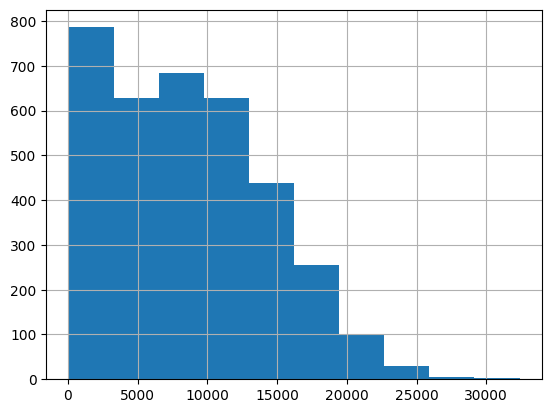

In [ ]:
df['built_area'].hist()

In [ ]:
df['modul_price'].min()

182.09251435778023

In [ ]:
#Featured engineering
df['weeks_wasted']=df['weeks_duration']-df['weeks_delay']

In [ ]:
import pandas as pd
preprocessed_TRAIN_csv=pd.read_csv('preprocessed_TRAIN_csv')
df['weeks_wasted']=df['weeks_duration']-df['weeks_delay']
preprocessed_TRAIN_csv.insert(1,'weeks_wasted',weeks_wasted)
preprocessed_TRAIN_csv.head()

NameError: name 'weeks_wasted' is not defined

In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
df

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...,...
3550,3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,3553,5694.837811,617.497125,COMMERCIAL,7,88


In [ ]:
! ls

CONSTADEX.ipynb					  preprocessed_const_csv  TRAIN_csv
construction-management-terms-and-parameters.zip  preprocessed_TRAIN_csv  TRAIN_scaled_CSV
drive						  sample_data
Memoria_ConstADEX_.pdf				  TEST_const_csv


In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
# df=pd.read_csv('/path/to/your/file/preprocessed_TRAIN_csv')
df

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...,...
3550,3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,3553,5694.837811,617.497125,COMMERCIAL,7,88


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/gdrive/My\ Drive

ls: cannot access '/content/gdrive/My Drive': No such file or directory


In [ ]:
! kaggle datasets download -d vierohernandez/construction-management-terms-and-parameters

Dataset URL: https://www.kaggle.com/datasets/vierohernandez/construction-management-terms-and-parameters
License(s): CC-BY-NC-SA-4.0
construction-management-terms-and-parameters.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
! unzip construction-management-terms-and-parameters.zip

Archive:  construction-management-terms-and-parameters.zip
replace CONSTADEX.ipynb? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
df

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...,...
3550,3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,3553,5694.837811,617.497125,COMMERCIAL,7,88


In [ ]:
to_drop=['Unnamed: 0', 'typology']
df.drop(to_drop, inplace=True, axis=1)

In [ ]:
df.head()

,built_area,modul_price,weeks_delay,weeks_duration
0,16971.669353,800.717684,0,69
1,12434.613919,680.061254,2,92
2,11003.411065,1190.379098,1,45
3,10423.124959,987.449779,4,35
4,22990.708329,564.466572,6,85


In [ ]:
#Featured engineering
df['weeks_productive']=df['weeks_duration']-df['weeks_delay']

In [ ]:
df.head()

,built_area,modul_price,weeks_delay,weeks_duration,weeks_productive
0,16971.669353,800.717684,0,69,69
1,12434.613919,680.061254,2,92,90
2,11003.411065,1190.379098,1,45,44
3,10423.124959,987.449779,4,35,31
4,22990.708329,564.466572,6,85,79


In [ ]:
df.index.is_unique
True

True

In [ ]:
df1=df.copy()

In [ ]:
df1.head()

,built_area,modul_price,weeks_delay,weeks_duration,weeks_productive
0,16971.669353,800.717684,0,69,69
1,12434.613919,680.061254,2,92,90
2,11003.411065,1190.379098,1,45,44
3,10423.124959,987.449779,4,35,31
4,22990.708329,564.466572,6,85,79


In [ ]:
df1=df1.dropna(subset=['built_area', 'modul_price', 'weeks_duration', 'weeks_delay'])

In [ ]:
df1.isnull().sum() #check if there are any null values left

built_area          0
modul_price         0
weeks_delay         0
weeks_duration      0
weeks_productive    0
dtype: int64

In [ ]:
print(df1.columns)

Index(['built_area', 'modul_price', 'weeks_delay', 'weeks_duration',
       'weeks_productive'],
      dtype='object')


In [ ]:
# to_drop=['weeks_wasted']
# df1.drop(to_drop, inplace=True, axis=1)

In [ ]:
df.head()

,built_area,modul_price,weeks_delay,weeks_duration,weeks_productive
0,16971.669353,800.717684,0,69,69
1,12434.613919,680.061254,2,92,90
2,11003.411065,1190.379098,1,45,44
3,10423.124959,987.449779,4,35,31
4,22990.708329,564.466572,6,85,79


In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_const_csv')
df.head()

,Unnamed: 0,built_area,modul_price,weeks_delay,weeks_duration,typology
0,0,55.44,1343.02,33,42,DETACHED
1,1,169.40,1019.86,49,66,DETACHED
2,2,74.44,812.23,13,23,DETACHED
3,3,617.24,1461.97,6,44,OTHERS
4,4,395.42,978.32,20,19,DETACHED


In [ ]:
import pandas as pd
df=pd.read_csv('TRAIN_csv')
df.head()

,Unnamed: 0,built_area,modul_price,weeks_duration,DETACHED,COLLECTIVE,COMMERCIAL,OTHERS,DELAYED
0,0,180.410508,586.869214,44,1,0,0,0,1
1,1,122.405353,759.672381,44,1,0,0,0,1
2,2,52.059159,577.329843,13,1,0,0,0,0
3,3,157.164940,445.906501,45,1,0,0,0,1
4,4,214.588272,542.401146,15,1,0,0,0,0


In [ ]:
import pandas as pd
df=pd.read_csv('TEST_const_csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,built_area,modul_price,weeks_duration,DETACHED,COLLECTIVE,COMMERCIAL,OTHERS,DELAYED
0,0,0,55.44,1343.02,42,1,0,0,0,1
1,1,1,169.40,1019.86,66,1,0,0,0,1
2,2,2,74.44,812.23,23,1,0,0,0,1
3,3,3,617.24,1461.97,44,0,0,0,1,0
4,4,4,395.42,978.32,19,1,0,0,0,1


In [ ]:
import pandas as pd
df=pd.read_csv('TRAIN_scaled_CSV')
df.head()

,Unnamed: 0,built_area,modul_price,weeks_duration,DETACHED,COLLECTIVE,COMMERCIAL,OTHERS,DELAYED
0,0,-1.417359,-0.581123,-0.490790,1,0,0,0,1
1,1,-1.427223,0.118484,-0.490790,1,0,0,0,1
2,2,-1.439186,-0.619744,-2.009743,1,0,0,0,0
3,3,-1.421312,-1.151822,-0.441792,1,0,0,0,1
4,4,-1.411547,-0.761156,-1.911746,1,0,0,0,0


In [ ]:
df1.head()

,built_area,modul_price,weeks_delay,weeks_duration,weeks_productive
0,16971.669353,800.717684,0,69,69
1,12434.613919,680.061254,2,92,90
2,11003.411065,1190.379098,1,45,44
3,10423.124959,987.449779,4,35,31
4,22990.708329,564.466572,6,85,79


In [ ]:
import pandas as pd
df=pd.read_csv('preprocessed_TRAIN_csv')
df.head()

,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85


In [ ]:
print(df1.columns)

Index(['built_area', 'modul_price', 'weeks_delay', 'weeks_duration',
       'weeks_productive'],
      dtype='object')


In [ ]:
to_drop=['Unnamed: 0', 'typology']
df.drop(to_drop, inplace=True, axis=1)
df.head()

,built_area,modul_price,weeks_delay,weeks_duration
0,16971.669353,800.717684,0,69
1,12434.613919,680.061254,2,92
2,11003.411065,1190.379098,1,45
3,10423.124959,987.449779,4,35
4,22990.708329,564.466572,6,85


In [ ]:
#Featured engineering
df['weeks_productive']=df['weeks_duration']-df['weeks_delay']

In [ ]:
df.head()

,built_area,modul_price,weeks_delay,weeks_duration,weeks_productive
0,16971.669353,800.717684,0,69,69
1,12434.613919,680.061254,2,92,90
2,11003.411065,1190.379098,1,45,44
3,10423.124959,987.449779,4,35,31
4,22990.708329,564.466572,6,85,79


<Axes: title={'center': 'Pearson Correlation of features'}>

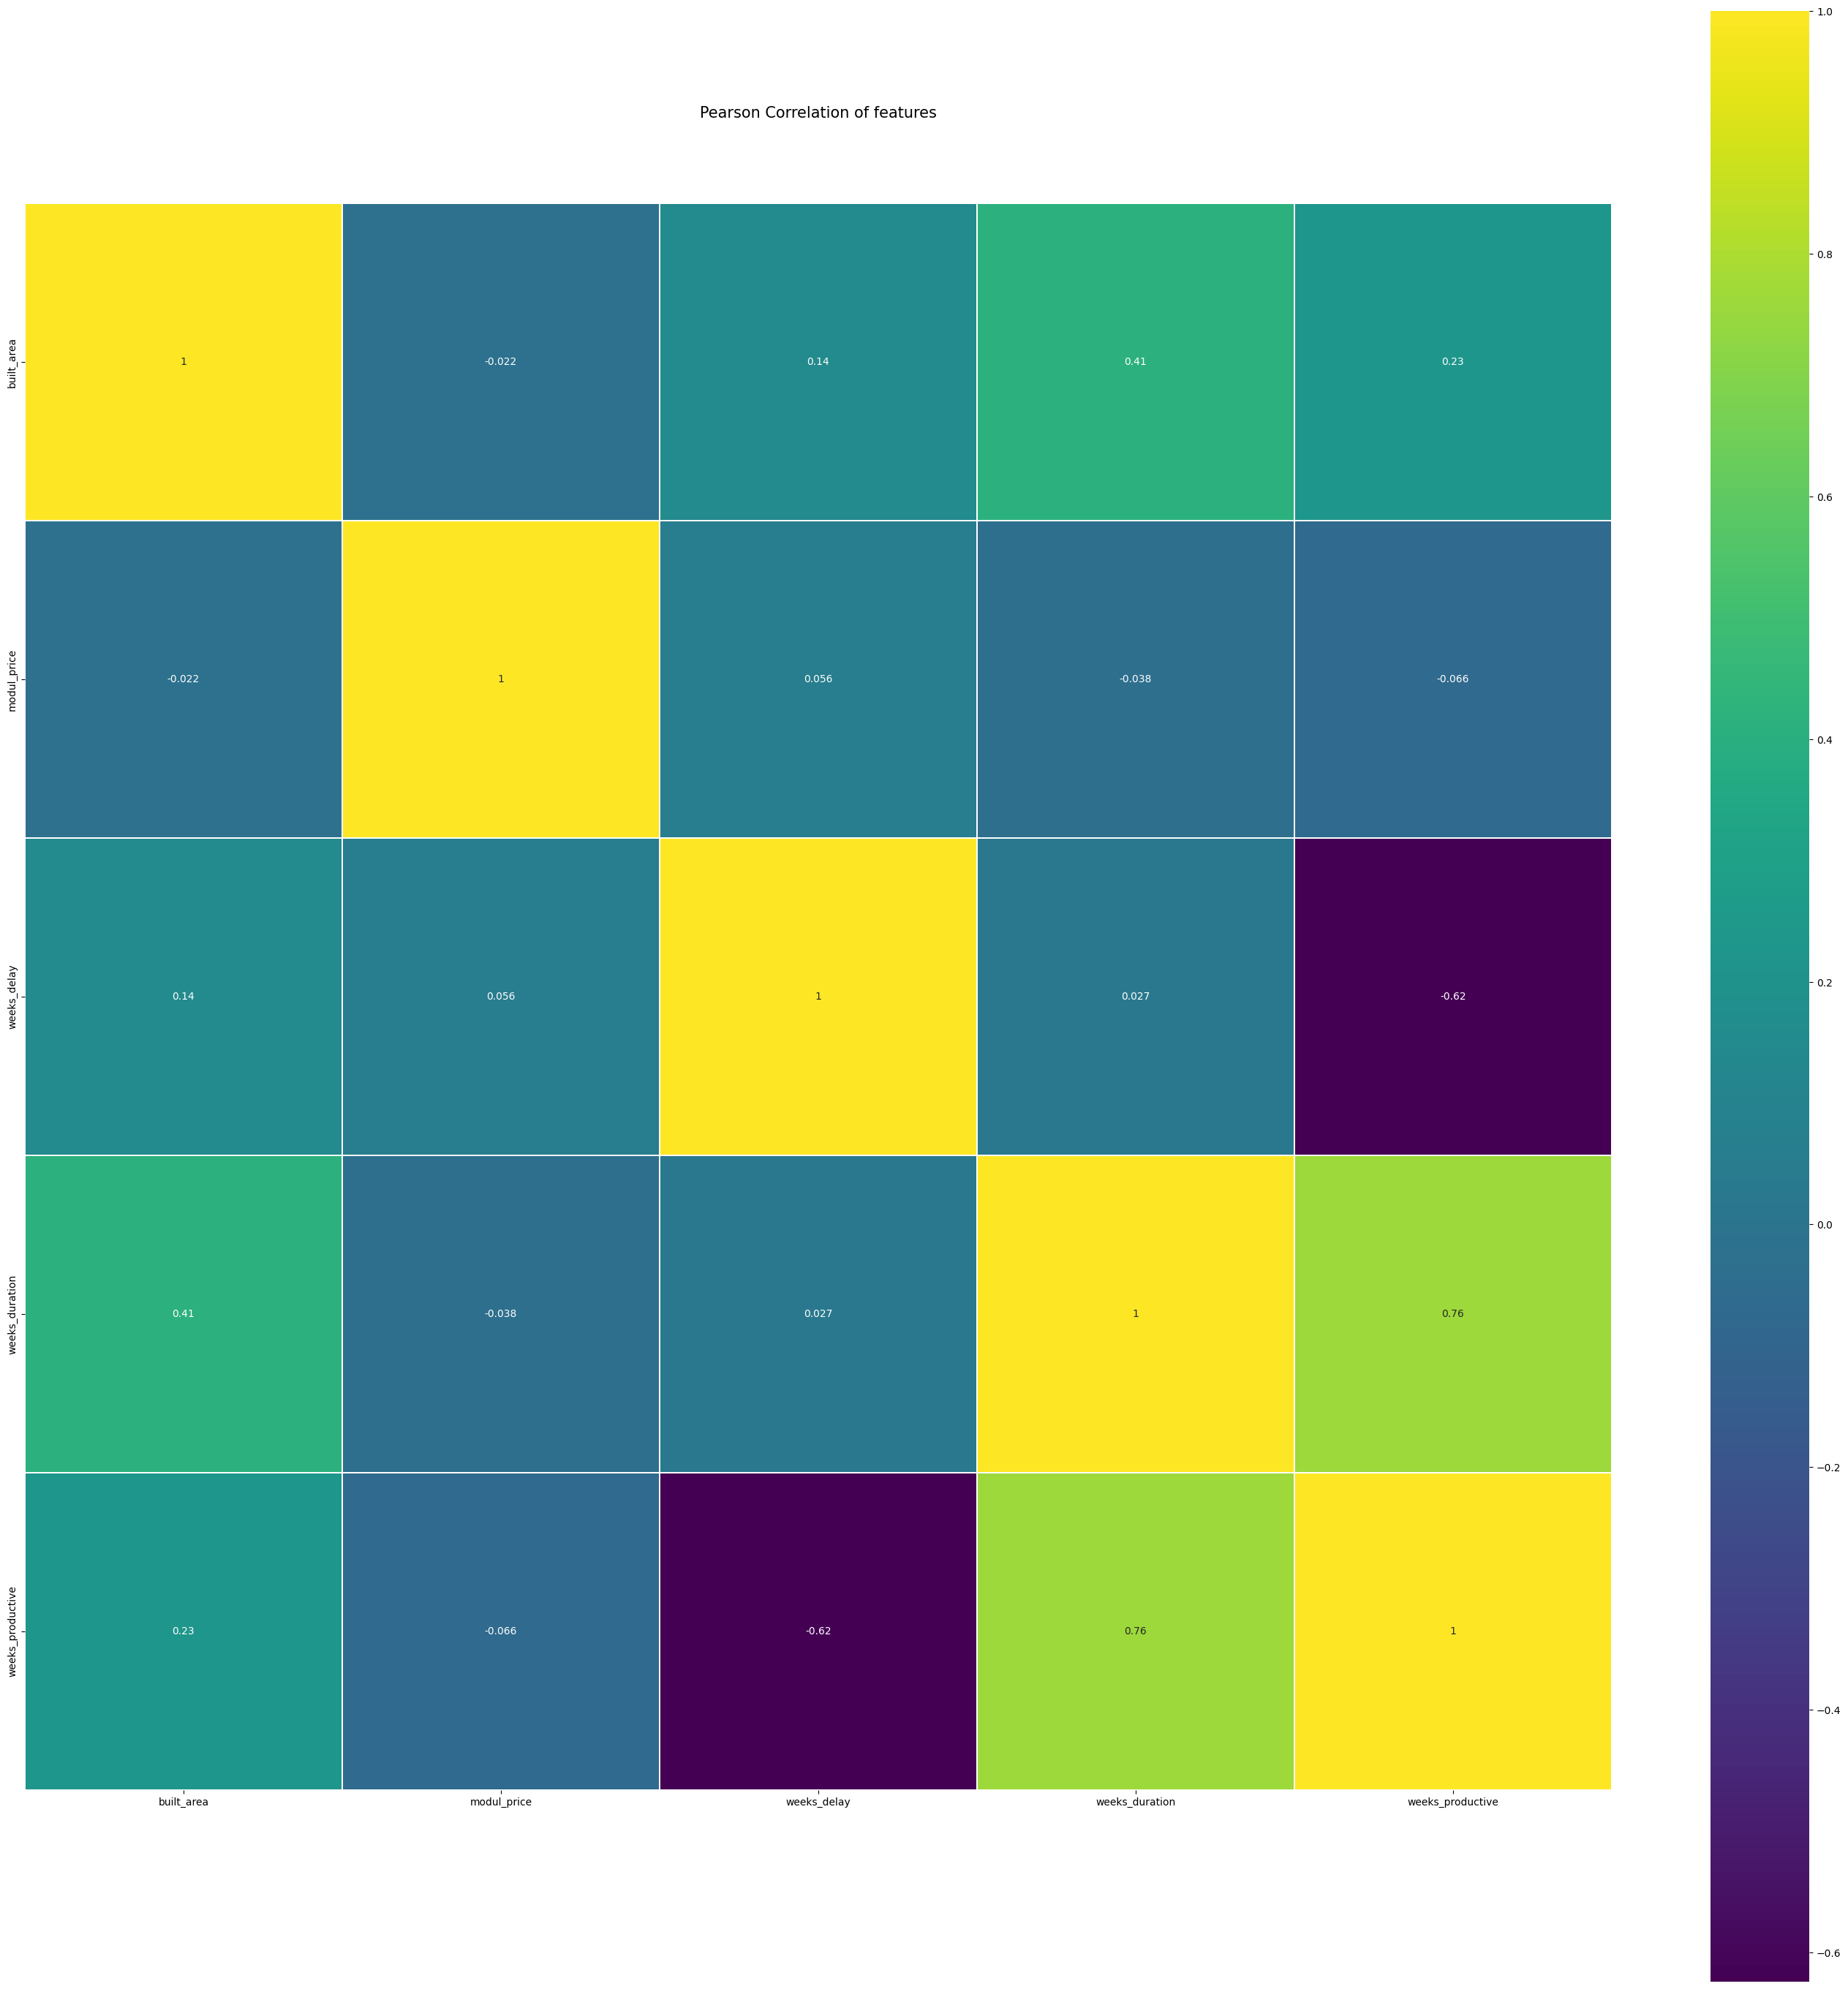

In [ ]:
#Statistics and Variable selection-to decide about which columns to pick on final model,
#a correlation modelis done
#creating correlation matrix
import matplotlib.pyplot as plt
import seaborn as sns
colormap=plt.cm.viridis
plt.figure(figsize=(35,35))
plt.title('Pearson Correlation of features', y=1.05, size=15)
sns.heatmap(df.corr(), linewidths=0.1, vmax=1.0,
            square=True, cmap=colormap, linecolor='white', annot=True)

In [ ]:
df['weeks_productive']=df['weeks_duration']-df['weeks_delay']
df1=df[['built_area', 'modul_price', 'weeks_delay', 'weeks_duration', 'weeks_productive']]
#df1.shape
df.head()

,built_area,modul_price,weeks_delay,weeks_duration,weeks_productive
0,16971.669353,800.717684,0,69,69
1,12434.613919,680.061254,2,92,90
2,11003.411065,1190.379098,1,45,44
3,10423.124959,987.449779,4,35,31
4,22990.708329,564.466572,6,85,79


In [ ]:
#Models
#we tested with muliclass trying to predict the whole 4 columns. As biases are included,
#we decided to leave it for final analysis
#Decision Tree: Multi Class Classification,grid search,Decisiontree:binomial classification
#Random Forest:Muilti Class Classification,Binomial Classification,random grid search
#Training data is used to train ml model, the more it has better it can make predictions
#-built_area, weeks_productive(manpower), weeks_duration(timeset to do work)
#Testing data is used to evaluate the performance of the model-modul_price
# Best result was produced from SVM and Random Forest for Multi Class
# Classification

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#first starting with Model: Decision Tree Multi Class Classification
#we plotting built area(x) against weeks duration y
y=df1.built_area
x=df1.drop('built_area',axis=1)
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)#test&train

In [ ]:
#checking size of dataset
print('Shape of X_train=>',x_train.shape)
print('Shape of X_test=>', x_test.shape)
print('Shape of Y_train=>',y_train.shape)
print('Shape of Y_test=>', y_test.shape)

Shape of X_train=> (2844, 4)
Shape of X_test=> (711, 4)
Shape of Y_train=> (2844,)
Shape of Y_test=> (711,)


In [ ]:
#testing with regular decision tree
from sklearn.tree import DecisionTreeClassifier
clf=DecisionTreeClassifier(random_state=100)
clf.fit(x_train,y_train)
y_pred=clf.predict(x_test)#train decision tree classifier

ValueError: Unknown label type: 'continuous'

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)#test&train
from sklearn.metrics import accuracy_score, classification_report,f1_score
import numpy as np

clf=DecisionTreeClassifier(random_state=100)
clf.fit(x_train,y_train)
y_pred=clf.predict(x_test)#train decision tree classifier

preds=clf.predict(x_test)#predict respone
print(accuracy_score(y_test,preds))
print(accuracy_score(y_train,clf.predict(x_train)))

print('\nClassification Report\n')
print(classification_report(y_test,preds))
f1_score(y_test,y_pred,average='weighted',labels=np.unique(y_pred))

ValueError: Unknown label type: 'continuous'

In [ ]:
#using parametersfrom the grid search to create the model
clf=DecisionTreeClassifier(criterion='entropy',max_depth=10,min_samples_leaf=1,min_samples_split=2,random_state=100)
clf.fit(x_train,y_train)
y_train_pred=clf.predict(x_train)#train decision tree classifier
y_test_pred=clf.predict(x_test)#testand train score are closer

print(accuracy_score(y_train,y_train_pred))
print(accuracy_score(y_test,y_test_pred))
print('\nClassification Report\n')
print(classification_report(y_test,y_test_pred))

ValueError: Unknown label type: 'continuous'

In [ ]:
#visual representation of the model
!pip install pydotplus

from io import StringIO
from sklearn.tree import export_graphviz
import graphviz
from IPython.display import Image
import pydotplus

xvar=df1.drop('weeks_duration',axis=1)
feature_cols=xvar.columns
dot_data=StringIO()
export_graphviz(clf,out_file=dot_data,filled=True,rounded=True,feature_names=feature_cols)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
#!sfdp -Tsvg -Goverlap=prism input.dot -o output.svg -Goverlap=prism #make image large
Image(graph.create_png())

AttributeError: 'DecisionTreeClassifier' object has no attribute 'tree_'

In [ ]:
#using grid dearch, we tried to find features that would get the best accuracy rate
feat_importance=clf.tree_.compute_feature_importances(normalize=False)
feat_imp_dict=dict(zip(feature_cols,clf.feature_importances_))
feat_imp=pd.DataFrame.from_dict(feat_imp_dict,orient='index')
feat_imp.rename(columns={0:'FeatureImportance'}, inplace=True)
feat_imp.sort_values(by='FeatureImportance',ascending=False).head(6)#top 20 impacting decision tree split

In [ ]:
sample_data = {'Nash_building_group': np.random.choice(range(0,30,1), size=(5)),
             'built_area': np.random.choice(range(0,30,1), size=(5)),
             'modul_price': np.random.choice(range(0,300,1), size=(5)),
             'weeks_delay': np.random.choice(range(0,30,1), size=(5)),
             'weeks_duration': np.random.choice(range(0,30,1), size=(5)),
             'weeks_productive': np.random.choice(range(0,30,1), size=(5))}

sample = pd.DataFrame(sample_data)
sample #sample dataset

In [ ]:
# Rename columns to match the original training data
sample = sample.rename(columns={'built_area': 'Nash_building_group', 'weeks_productive': 'weeks_duration'})

# Add any missing columns and fill them with appropriate values (e.g., 0)
missing_cols = set(feature_cols) - set(sample.columns)
for col in missing_cols:
    sample[col] = 0

# Reorder columns to match the order used during training
sample = sample[feature_cols]

# Now predict using the modified sample DataFrame
ynew = clf.predict(sample)
print(ynew)

In [ ]:
#Decision Tree: Binomial Classification
#we received best accuracy rate when we used gini creation, max depth of 3,
#min samples leaf of 1 and min samples split of 2


In [ ]:
#performing pickle testing in order to test the object
import pickle
numbers_list=[1,2,3,4,5]
list_pickle_path='list_pickle.pkl'

list_pickle=open(list_pickle_path,'wb')
pickle.dump(numbers_list,list_pickle)
list_pickle.close()

In [ ]:
#unpickling the list object
#Need to open the pickled list object into read mode

list_pickle_path='list_pickle.pkl'
list_unpickle=open(list_pickle_path,'rb')
#load the unpickle object into a variable
numbers_list=pickle.load(list_unpickle)
print("Numbers list: ",numbers_list)

Numbers list:  [1, 2, 3, 4, 5]


In [ ]:
import pickle
import pandas as pd
#scikit-learn method to split the dataset into train and test dataset
from sklearn.model_selection import train_test_split
#Scikit-learn method to implement decision tree classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
import pandas as pd

#load the dataset
preprocessed_TRAIN_csv=pd.read_csv("https://www.kaggle.com/datasets/vierohernandez/construction-management-terms-and-parameters?resource=download&select=preprocessed_TRAIN_csv",on_bad_lines='skip')
print("Dataset Length:", len(df1))
print("Dataset shape:", df1.shape)

categorical_cols=['built_area','modul_price','weeks_delay','weeks_duration','weeks_productive']
label_encoder=LabelEncoder()
for col in categorical_cols:
    df1[col]=label_encoder.fit_transform(df1[col])
df1.head()

for col in df1.columns:
  df1[col]=pd.to_numeric(df1[col],errors='coerce').fillna(0)

#split the dataset into train and test dataset
X=df1.values[:, 1:10]
Y=df1.values[:,0]

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
#Decision model with Gini index critiria
decision_tree_model=DecisionTreeClassifier(criterion='gini')
decision_tree_model.fit(X_train,y_train)
print("Decision Tree classifier:: ", decision_tree_model)


Dataset Length: 3555
Dataset shape: (3555, 5)
Decision Tree classifier::  DecisionTreeClassifier()


In [ ]:
#Dump the trained decision tree classifier with Pickle
decision_tree_pkl_filename = 'decision_tree_classifier_20170212.pkl'
# Open the file to save as pkl file
decision_tree_model_pkl = open(decision_tree_pkl_filename, 'wb')
pickle.dump(decision_tree_model, decision_tree_model_pkl)
# Close the pickle instances
decision_tree_model_pkl.close()

In [ ]:
#loading the scikit learn models with Pickle
decision_tree_model_pkl = open(decision_tree_pkl_filename, 'rb')
decision_tree_model = pickle.load(decision_tree_model_pkl)
print ("Loaded Decision tree model :: ", decision_tree_model)

Loaded Decision tree model ::  DecisionTreeClassifier()


In [ ]:
# Sample data
sample_data = {'built_area': [1], 'modul_price': [2], 'weeks_delay': [3], 'weeks_duration': [4], 'weeks_productive': [5]}

# Create a DataFrame from the sample data
sample_df = pd.DataFrame(sample_data)

# Make predictions using the loaded model
predictions = decision_tree_model.predict(sample_df)

# Print the predictions
print("Predictions:", predictions)

Predictions: [57]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [ ]:
Y = df.weeks_duration #setting Y variable
X = df.drop('weeks_duration', axis = 1) #dropping status and setting features
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)#test and train dataset

In [ ]:
# testing with regular decision tree
clf = DecisionTreeClassifier(random_state = 100)
clf = clf.fit(X_train, Y_train)#train decison tree classifier

In [ ]:
preds = clf.predict(X_test) # predict the response for test data

print(accuracy_score(Y_test,preds))
print(accuracy_score(Y_train,clf.predict(X  _train)))

print('\nClassification Report\n')
print(classification_report(Y_test, preds, target_names=['weeks_duration']))
#accuracy score is high for training dataset which shows that it might be overfitting

SyntaxError: invalid syntax. Perhaps you forgot a comma? (<ipython-input-87-34ffd05df366>, line 4)

In [ ]:
#grid.best_estimator_
#using paramerters from the grid search to create the model
clf = DecisionTreeClassifier(criterion = 'entropy', max_depth = 5, min_samples_leaf = 1, min_samples_split=2, random_state=40)
clf.fit(X_train,Y_train) #fitting into the model
y_train_pred=clf.predict(X_train)
y_test_pred=clf.predict(X_test)
#test and train score are closer

print(accuracy_score(Y_train,y_train_pred),accuracy_score(Y_test,y_test_pred)) #accuracy score of test and train data.
print('\nClassification Report\n')
print(classification_report(Y_test, y_test_pred, target_names=['weeks_duration'])) # classification report

0.12658227848101267 0.06188466947960619

Classification Report



ValueError: Number of classes, 94, does not match size of target_names, 1. Try specifying the labels parameter

In [ ]:
import pandas as pd

In [ ]:
dataset='preprocessed_TRAIN_csv'
data=pd.read_csv(dataset,header=None)

In [ ]:
data.head()

,0,1,2,3,4,5
0,NaN,built_area,modul_price,typology,weeks_delay,weeks_duration
1,0.0,16971.66935259308,800.7176838676573,COLLECTIVE,0,69
2,1.0,12434.6139188663,680.0612537771135,COMMERCIAL,2,92
3,2.0,11003.411064655009,1190.3790980630483,COLLECTIVE,1,45
4,3.0,10423.124958618257,987.4497793846988,OTHERS,4,35


In [ ]:
x=data.drop(['NaN'],['typology'], axis=1)
data......